# 06 — Transition markers and interval evidence

**Purpose:** construct and inspect transition evidence before assigning ownership. This notebook is not the probability model and not the final submission runner. It identifies candidate intervals, restart boundaries, anchors, and unresolved contests that 07 converts into weighted hypotheses.

The concrete problem is that a nearest-player change or one noisy touch can look like a turnover. We therefore mark the interval and inspect forward/backward evidence—ball motion, player approach, density, arrival margin, missingness, and post-touch control—before allowing a switch.

- Dead-ball/restart handling is separated from open-play transition evidence.
- Study the transition window, not only the transition frame.
- Inspect: ball speed, acceleration, direction, missingness, player paths, density, closing speed, arrival margin.
- CONTESTED means the evidence is unresolved; it is not a weak H/A label.
- A candidate switch is not confirmed until the next touch/control evidence agrees.
- The public H/A boundary and the comfortable anchor may legitimately differ.

The output is evidence for the next layer: `observations → scenario evidence → transition/no-switch hypotheses`. George contributes bounded observed-gap confidence, flight support, dead-ball support, and residual uncertainty to this interval audit; it never selects H/A alone. See [07_probability_transition_model.ipynb](07_probability_transition_model.ipynb) for the score/softmax and calibration experiments.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.calculations.features import build_engineered_features
from possession_lab.temporal_rules import load_rules

features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())
gt = pd.read_csv(ROOT / 'evaluation/gt/BAR-ATH_possession_gt_public.csv').set_index('frame')['label']
frames = features.frame.astype(int)
features['gt_label'] = gt.reindex(frames).to_numpy()
transition = features.loc[features.gt_label.ne(features.gt_label.shift()) & features.gt_label.isin(['H','A'])].copy()
columns = [
    'frame', 'gt_label', 'scenario_context', 'ball_speed_derived_mps',
    'ball_acceleration_mps2', 'ball_direction_change_rad',
    'ball_distance_travelled_recent_m', 'candidate_opponent_density_5m',
    'landing_opponent_approach_speed_mps', 'arrival_time_margin_s',
    'direction_target_team', 'forecast_touch_team', 'anchor_team',
]
display(transition[[c for c in columns if c in transition]].tail(10))


,frame,gt_label,scenario_context,ball_speed_derived_mps,ball_acceleration_mps2,ball_direction_change_rad,ball_distance_travelled_recent_m,candidate_opponent_density_5m,landing_opponent_approach_speed_mps,arrival_time_margin_s,direction_target_team,forecast_touch_team,anchor_team
13785,13785,H,UNKNOWN,1.028862,-1.068816,0.004879,0.346333,1.0,1.157426,5.177043,H,NaN,NaN
14846,14846,A,BALL_IN_FLIGHT,8.254909,15.551925,0.021270,1.836387,2.0,0.000000,-2.359544,H,NaN,NaN
15346,15346,H,CONTESTED,3.858412,-6.477523,0.044248,1.422913,4.0,0.000000,-3.564488,H,NaN,NaN
15365,15365,A,BALL_IN_FLIGHT,8.183261,14.759874,0.018904,1.900551,2.0,0.000000,1.145188,A,NaN,NaN
15766,15766,H,CONTESTED,1.352950,1.840034,0.173331,0.541702,1.0,1.204063,-1.361259,NaN,NaN,NaN
15799,15799,A,CONTESTED,6.166553,5.570054,0.053431,1.716538,1.0,1.431818,0.011081,A,NaN,NaN
16400,16400,A,PRESSURED_CONTROL,4.942804,16.268312,0.083781,1.021450,1.0,3.386951,-1.047185,A,NaN,NaN
17293,17293,H,RECEPTION_CANDIDATE,7.265487,-18.709660,0.020367,3.123881,1.0,NaN,0.233321,NaN,NaN,NaN
17838,17838,A,RESTART_LIVE_BOUNDARY,5.686446,-11.344660,0.003871,2.269151,1.0,NaN,-0.394095,H,NaN,NaN
18389,18389,H,RESTART_LIVE_BOUNDARY,4.945797,-7.202864,0.004410,1.886329,0.0,0.488848,28.145332,H,NaN,NaN


## Dead-ball/restart study

The D spell is difficult because the ball can be stopped, missing, or between a restart and its first controlled touch. Smart Tagging identifies the restart context, while speed, activity, ball activation, and the first receiver path determine when H/A evidence becomes usable. We therefore protect D during unresolved restart frames rather than forcing a fixed-duration hold.

restart context frame: 11097 type: Kick Off (Start)


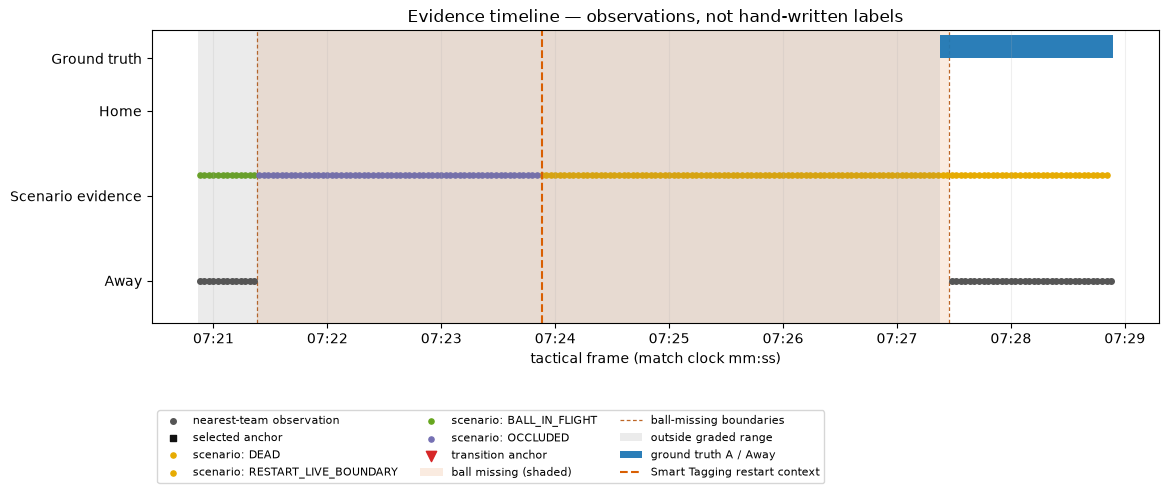

In [2]:
from possession_lab.calculations.plotting import plot_timeline_window
import matplotlib.pyplot as plt

restart_rows = features.loc[features.restart_context & features.frame.between(int(gt.index.min()), int(gt.index.max()))]
if restart_rows.empty:
    print('No Smart Tagging restart context overlaps the public audit interval.')
else:
    restart_frame = int(restart_rows.frame.iloc[0])
    start_frame = max(int(features.frame.min()), restart_frame - 75)
    end_frame = min(int(features.frame.max()), restart_frame + 125)
    print('restart context frame:', restart_frame, 'type:', features.loc[features.frame.eq(restart_frame), 'restart_type'].iloc[0])
    fig, ax = plt.subplots(figsize=(13, 3.8))
    plot_timeline_window(features, start_frame, end_frame, ground_truth=gt, ax=ax)
    ax.axvline(restart_frame, color='#d95f02', linestyle='--', label='Smart Tagging restart context')
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=3, fontsize=8)
    plt.show()

## Public ground-truth turnover windows

The switch frame is only the centre of the study. We inspect several public H/A turnovers with a symmetric look-back/look-forward window. The ground-truth strip is shown for temporal orientation only; the feature table remains built without public labels.

public turnover 11351: A -> H


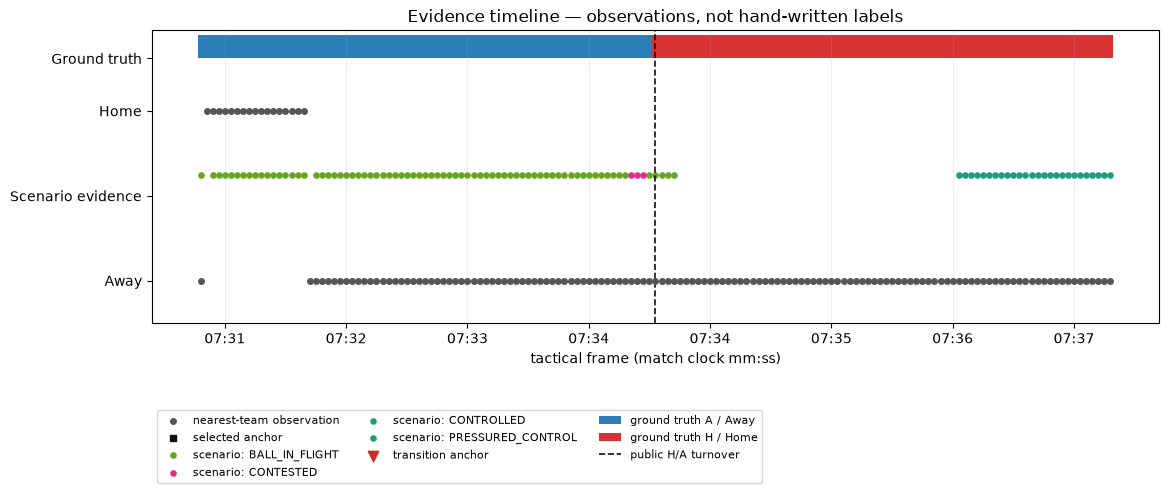

public turnover 11553: H -> A


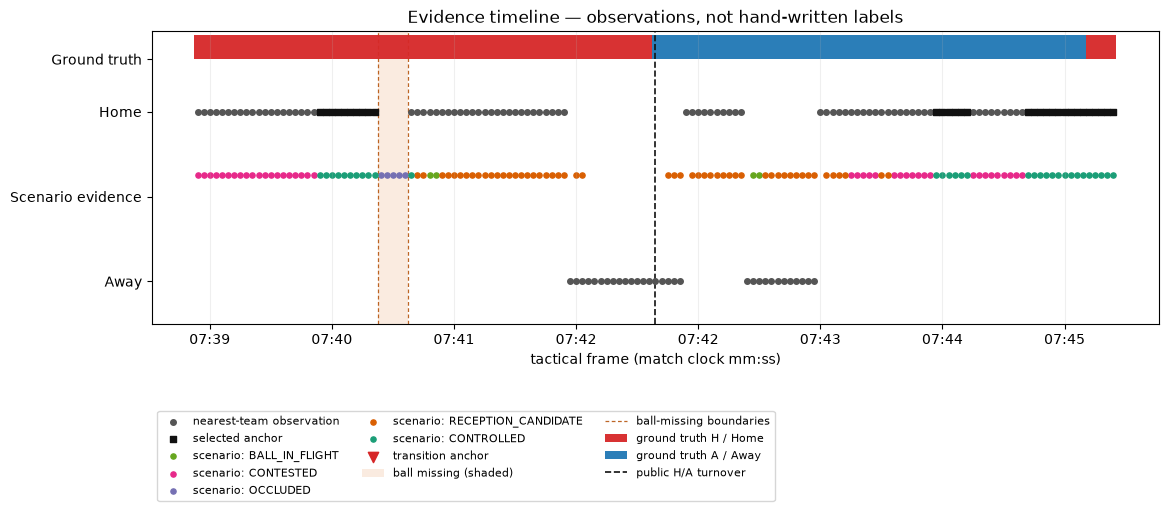

public turnover 11624: A -> H


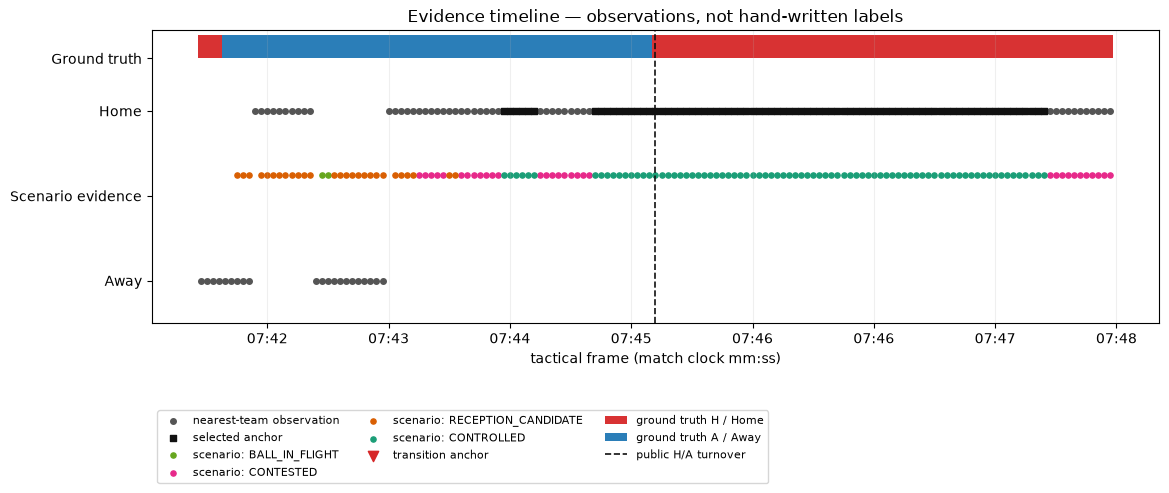

In [3]:
from possession_lab.calculations.plotting import plot_timeline_window
import matplotlib.pyplot as plt

gt_known = gt.dropna()
gt_h_a = gt_known[gt_known.isin(['H', 'A'])]
gt_switches = gt_h_a.index[(gt_h_a != gt_h_a.shift()) & gt_h_a.shift().isin(['H', 'A'])]
if len(gt_switches) == 0:
    print('No public H/A turnovers are available in this checkout.')
else:
    for turnover_frame in list(gt_switches[:3]):
        turnover_frame = int(turnover_frame)
        start_frame = max(int(features.frame.min()), turnover_frame - 75)
        end_frame = min(int(features.frame.max()), turnover_frame + 75)
        previous = gt_h_a.loc[gt_h_a.index < turnover_frame].iloc[-1]
        current = gt_h_a.loc[turnover_frame]
        print(f'public turnover {turnover_frame}: {previous} -> {current}')
        fig, ax = plt.subplots(figsize=(13, 3.8))
        plot_timeline_window(features, start_frame, end_frame, ground_truth=gt, ax=ax)
        ax.axvline(turnover_frame, color='#111111', linestyle='--', linewidth=1.2, label='public H/A turnover')
        ax.legend(loc='upper left', bbox_to_anchor=(0, -0.28), ncol=3, fontsize=8)
        plt.show()